# Assignment 2 — Region Operations and Spatial Enhancement

Implements connected regions, histogram equalisation, smoothing, and sharpening.

This notebook is intentionally modular. **Style 1** uses OpenCV operations; **Style 2** uses OpenCV only for reading and Matplotlib for display, while the image-processing logic is written with arrays, loops, queues, and formulas.

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

LAB_DIR = Path.cwd()

def show_images(images, titles, cmap="gray", figsize=(14, 4)):
    """Display a sequence of images consistently in a notebook."""
    fig, axes = plt.subplots(1, len(images), figsize=figsize)
    axes = np.atleast_1d(axes)
    for axis, image, title in zip(axes, images, titles):
        axis.imshow(image, cmap=cmap)
        axis.set_title(title)
        axis.axis("off")
    plt.tight_layout()
    plt.show()


## Style 1 — OpenCV built-in operations

In [2]:
def regions_cv(binary, connectivity=8):
    count, labels, stats, _ = cv2.connectedComponentsWithStats(binary.astype(np.uint8), connectivity)
    return labels, stats[1:]

def enhance_cv(image):
    equalized = cv2.equalizeHist(image)
    mean = cv2.blur(image, (3, 3))
    median = cv2.medianBlur(image, 3)
    laplacian = cv2.Laplacian(image, cv2.CV_32F)
    sharpened = np.clip(image.astype(np.float32) - laplacian, 0, 255).astype(np.uint8)
    return equalized, mean, median, sharpened


## Style 2 — DSA/manual implementation

In [3]:
def labels_manual(binary, connectivity=8):
    labels = np.zeros(binary.shape, np.int32)
    offsets = [(-1, 0), (1, 0), (0, -1), (0, 1)]
    if connectivity == 8: offsets += [(-1, -1), (-1, 1), (1, -1), (1, 1)]
    label = 0
    for r in range(binary.shape[0]):
        for c in range(binary.shape[1]):
            if binary[r, c] and labels[r, c] == 0:
                label += 1; stack = [(r, c)]; labels[r, c] = label
                while stack:
                    x, y = stack.pop()
                    for dx, dy in offsets:
                        nx, ny = x + dx, y + dy
                        if 0 <= nx < binary.shape[0] and 0 <= ny < binary.shape[1] and binary[nx, ny] and labels[nx, ny] == 0:
                            labels[nx, ny] = label; stack.append((nx, ny))
    return labels, label

def histogram_equalize_manual(image):
    hist = [0] * 256
    for value in image.ravel(): hist[int(value)] += 1
    cdf, running = [0] * 256, 0
    for i, count in enumerate(hist): running += count; cdf[i] = running
    first = next((value for value in cdf if value), 0)
    scale = 255 / max(1, image.size - first)
    lut = np.array([round((value - first) * scale) if value else 0 for value in cdf], np.uint8)
    return lut[image]

def filter_manual(image, mode="mean", size=3):
    pad = size // 2; padded = np.pad(image, pad, mode="edge"); output = np.empty_like(image)
    for r in range(image.shape[0]):
        for c in range(image.shape[1]):
            window = padded[r:r + size, c:c + size]
            output[r, c] = np.mean(window) if mode == "mean" else np.median(window)
    return output.astype(np.uint8)


## Demonstration

OpenCV regions: 92
Manual regions: 92


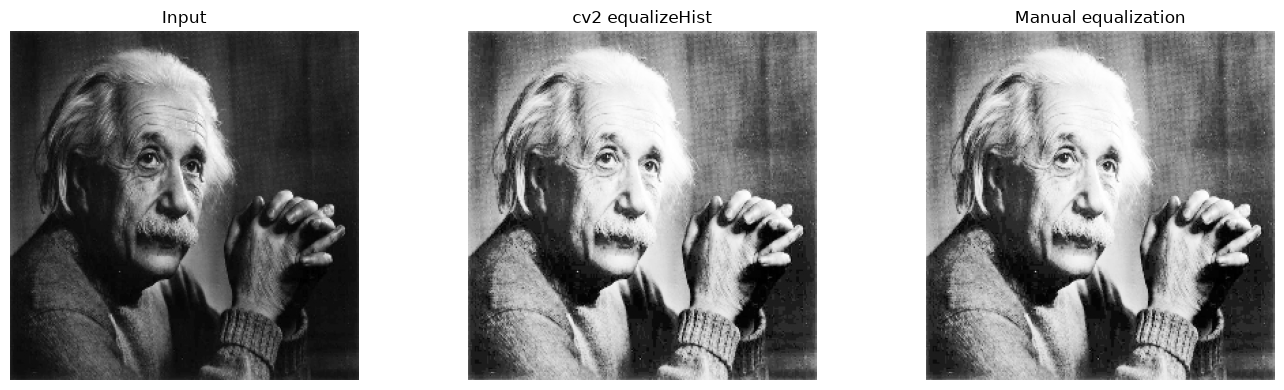

In [4]:
image = cv2.imread(str(LAB_DIR / "input.png"), cv2.IMREAD_GRAYSCALE)
if image is None: image = np.arange(64, dtype=np.uint8).reshape(8, 8) * 4
binary = (image > 100).astype(np.uint8)
print("OpenCV regions:", len(regions_cv(binary)[1]))
print("Manual regions:", labels_manual(binary)[1])
show_images([image, enhance_cv(image)[0], histogram_equalize_manual(image)], ["Input", "cv2 equalizeHist", "Manual equalization"])
